# First-leak acoustic analysis — post-first-leak healthy reference and DiD-style contrasts

**Run from:** `notebooks/`  
**Read original, untruncated CSVs:** `../data/2026-03-04/*.csv`  
**Write results:** `../results/first_leak_frequency_analysis_DiD_posthealthy/`

This is a revision of `first_leak_frequency_analysis_DiD.ipynb`. It retains the original first-leak paired comparison, statistical summaries, probe difference features, figures, DiD-style contrast plots and exploratory run-level inference. The analysis covers the **same nine frequencies in the previous executed results**, each for UUS, US, DS, DDS and three spatial differences (63 features).

**Changed control construction:** The *original untruncated* probe files are read. For each run/probe, the first consecutive block of `Leak Event=1` is located exactly as in `extract_through_first_leak.py`. The original pre/first-leak analysis only uses rows through the end of that block. Later rows with `Leak Event=0` and `Reynolds_level=150` are retained separately as **potential reference/control data**. Four-probe alignment uses original timestamps within runs; no interpolation.

For each treated run **T** and *different* reference run **C**, both at Reynolds level 150, the reported arithmetic contrast is

\[
[\operatorname{median}(T_{\mathrm{first\ leak}})-\operatorname{median}(T_{\mathrm{pre}})]-[\operatorname{median}(C_{\mathrm{healthy\ after}})-\operatorname{median}(C_{\mathrm{pre}})].
\]

**Important identification limitation:** This is an exploratory **DiD-style difference of changes**, **not a validated causal DiD**. The reference's later healthy episode is not contemporaneous with the treated run's first-leak episode; recovery/carryover and parallel trends have not been established. A `Leak Event=0` label does not establish acoustic recovery. No time-matched observations are claimed and no causal significance is claimed. The original run-level p-values are retained as exploratory, unadjusted statistics. **Boxplots show the raw healthy-before, first-leak, and healthy-after distributions so this assumption is visually inspectable.**


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display

# The same nine frequencies as the prior executed analysis (63 features = 9 × 7).
FREQUENCIES = ('f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000')
PROBES = ('UUS', 'US', 'DS', 'DDS')
PAIRS = (('UUS','US'), ('US','DS'), ('DS','DDS'))

# Notebook resides under notebooks/; input is the original, untruncated experiment files.
DATA = Path('../data/2026-03-04')
OUT = Path('../results/first_leak_frequency_analysis_DiD_posthealthy')
if not DATA.is_dir():
    raise FileNotFoundError(f'Data folder not found: {DATA.resolve()} (run the notebook from notebooks/)')
FILES = sorted(DATA.glob('*.csv'))
if not FILES:
    raise FileNotFoundError(f'No CSV files found in {DATA.resolve()}')
OUT.mkdir(parents=True, exist_ok=True)
print('Original input folder:', DATA.resolve())
print('Original CSV files found:', len(FILES))
print('Output:', OUT.resolve())


Original input folder: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/data/2026-03-04
Original CSV files found: 20
Output: /home/ubuntu/notebooks/Leak_Detection_v1/Leak_Detection/results/first_leak_frequency_analysis_DiD_posthealthy


## 1. Read original untruncated CSVs; retain first leak and later healthy observations separately

The initial and first-leak samples reproduce the original extractor's truncation boundary. Later healthy Reynolds-150 rows are **not discarded**: they remain available to the revised control construction. Original timestamps are used for synchronization, elapsed seconds are computed from each original file's first timestamp (as in the extractor). No additional samples are silently included in the first-leak treated group.

In [2]:
# Reproduce the original extractor's first consecutive leak-block boundary, without writing
# an intermediate truncated CSV. Keep the full, original file available for controls.
first_leak_pieces = []
after_healthy_pieces = []
input_inventory = []
for file in FILES:
    source = pd.read_csv(file, low_memory=False)
    source.columns = [re.split(r'[ǀ|｜¦]', str(c))[-1].strip() for c in source.columns]
    if source.columns.duplicated().any():
        raise ValueError(f'{file.name}: duplicate column names after normalization')
    source = source.rename(columns={'Reynolds_Level': 'Reynolds_level'})
    required_source = ['Date-Time', 'Reynolds_level', 'Leak Event', *FREQUENCIES]
    missing = [c for c in required_source if c not in source.columns]
    if missing:
        raise ValueError(f'{file.name}: missing columns {missing}')
    probe_match = re.match(r'^(UUS|DDS|US|DS)(?=\d|_|-|$)', file.stem, flags=re.I)
    if probe_match is None:
        raise ValueError(f'{file.name}: cannot determine probe from file name')
    probe = probe_match.group(1).upper()
    flags = pd.to_numeric(source['Leak Event'], errors='raise')
    if flags.isna().any() or not flags.isin([0, 1]).all():
        raise ValueError(f'{file.name}: Leak Event must be 0 or 1')
    level = pd.to_numeric(source['Reynolds_level'], errors='raise')
    if level.isna().any():
        raise ValueError(f'{file.name}: missing Reynolds_level')
    original_times = source['Date-Time'].copy()
    timestamps = pd.to_datetime(original_times, errors='raise')
    elapsed = (timestamps - timestamps.iloc[0]).dt.total_seconds()
    leak_positions = np.flatnonzero(flags.to_numpy() == 1)
    if len(leak_positions):
        first_start = int(leak_positions[0])
        first_end = first_start
        while first_end < len(source) and flags.iloc[first_end] == 1:
            first_end += 1
    else:
        first_start = None
        first_end = len(source)

    # Match extractor metadata and Date-Time / Date-Time-orig semantics exactly.
    source['Date-Time-orig'] = original_times
    source['Date-Time'] = elapsed
    source['file_name'] = file.stem
    source['probe'] = probe
    source['Reynolds_level'] = level
    source['Leak Event'] = flags
    first_leak_pieces.append(source.iloc[:first_end].copy())

    # This is the only additional data source used by the revised control construction.
    after = source.iloc[first_end:]
    after = after.loc[after['Leak Event'].eq(0) & after['Reynolds_level'].eq(150)].copy()
    after_healthy_pieces.append(after)
    input_inventory.append({
        'file': file.name, 'probe': probe,
        'first_leak_start_row': first_start,
        'first_leak_end_exclusive_row': first_end if first_start is not None else None,
        'post_first_leak_rows': len(source) - first_end,
        'post_first_leak_healthy_Re150_rows': len(after),
        'available_frequencies': ', '.join(
            freq for freq in FREQUENCIES
            if pd.to_numeric(after[freq], errors='coerce').notna().any()
        )
    })

input_inventory = pd.DataFrame(input_inventory)
input_inventory.to_csv(OUT / 'post_first_leak_healthy_inventory.csv', index=False)
print('Post-first-leak healthy rows per original file:')
display(input_inventory)

df = pd.concat(first_leak_pieces, ignore_index=True)
post_controls = pd.concat(after_healthy_pieces, ignore_index=True)

# Original validation and first-leak analysis variables: unchanged in meaning.
df.columns = [re.split(r'[ǀ|｜¦]', str(c))[-1].strip() for c in df.columns]
if df.columns.duplicated().any():
    raise ValueError('Duplicate column names after normalization')
df = df.rename(columns={'Reynolds_Level': 'Reynolds_level'})
required = ['file_name', 'probe', 'Date-Time', 'Date-Time-orig', 'Reynolds_level', 'Leak Event', *FREQUENCIES]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError('Missing columns: ' + str(missing))
df['file_name'] = df['file_name'].astype(str).str.replace(r'\.csv$', '', regex=True)
df['probe'] = df['probe'].astype(str).str.upper().str.strip()
df['run_id'] = df['file_name'].str.replace(r'^(UUS|US|DS|DDS)', '', regex=True)
df['timestamp'] = pd.to_datetime(df['Date-Time-orig'], errors='raise')
# Experimental elapsed seconds; originally used for cross-run matching.
df['elapsed_seconds'] = pd.to_numeric(df['Date-Time'], errors='raise')
for col in ['Reynolds_level', 'Leak Event', *FREQUENCIES]:
    df[col] = pd.to_numeric(df[col], errors='raise')
if df['Reynolds_level'].isna().any():
    raise ValueError('Missing Reynolds_level')
VALID_LEVELS = (12.5, 25.0, 50.0, 100.0, 150.0)
unknown_levels = sorted(set(df['Reynolds_level'].dropna().unique()) - set(VALID_LEVELS) - {0.0})
if unknown_levels:
    raise ValueError(f'Unexpected Reynolds_level values: {unknown_levels}')
print('Reynolds levels in input:', sorted(df['Reynolds_level'].unique()))
zero_rows = int(df['Reynolds_level'].eq(0).sum())
df = df.loc[df['Reynolds_level'].ne(0)].copy()
print('Excluded Reynolds_level=0 rows:', zero_rows)
print('Retained Reynolds levels:', sorted(df['Reynolds_level'].unique()))
if df['Leak Event'].isna().any() or not df['Leak Event'].isin([0,1]).all():
    raise ValueError('Leak Event must contain only 0 or 1')
if not df['probe'].isin(PROBES).all():
    raise ValueError('Unknown probes: ' + str(df.loc[~df['probe'].isin(PROBES), 'probe'].unique()))
if df[['run_id','probe','timestamp']].isna().any().any():
    raise ValueError('Missing run/probe/timestamp')
if df.duplicated(['run_id','probe','elapsed_seconds']).any():
    raise ValueError('Duplicate elapsed seconds within run/probe')
if df.duplicated(['run_id','probe','timestamp']).any():
    raise ValueError('Duplicate timestamp within run/probe')
print('Rows through first leak:', len(df), '| runs:', df.run_id.nunique(), '| probes:', df.probe.nunique())
display(df.groupby(['run_id','probe','Leak Event']).size().rename('rows').reset_index())

# Prepare later healthy rows with the same names and timestamp representation as df.
post_controls['file_name'] = post_controls['file_name'].astype(str)
post_controls['probe'] = post_controls['probe'].astype(str).str.upper().str.strip()
post_controls['run_id'] = post_controls['file_name'].str.replace(r'^(UUS|US|DS|DDS)', '', regex=True)
post_controls['timestamp'] = pd.to_datetime(post_controls['Date-Time-orig'], errors='raise')
post_controls['elapsed_seconds'] = pd.to_numeric(post_controls['Date-Time'], errors='raise')
for col in ['Reynolds_level', 'Leak Event', *FREQUENCIES]:
    post_controls[col] = pd.to_numeric(post_controls[col], errors='raise')
if post_controls.duplicated(['run_id','probe','timestamp']).any():
    raise ValueError('Duplicate timestamp in post-first-leak healthy data')
print('Later healthy Re=150 probe rows:', len(post_controls))


Post-first-leak healthy rows per original file:


,file,probe,first_leak_start_row,first_leak_end_exclusive_row,post_first_leak_rows,post_first_leak_healthy_Re150_rows,available_frequencies
0,DDS1211_1.csv,DDS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
1,DDS1212_1.csv,DDS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
2,DDS1212_2.csv,DDS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
3,DDS1213_1.csv,DDS,3300,3900,6901,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
4,DDS1213_2.csv,DDS,3000,3600,6300,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
5,DS1211_1.csv,DS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
6,DS1212_1.csv,DS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
7,DS1212_2.csv,DS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
8,DS1213_1.csv,DS,3300,3900,6901,300,"f160, f200, f250, f315, f400, f500, f630, f800..."
9,DS1213_2.csv,DS,3000,3600,7201,300,"f160, f200, f250, f315, f400, f500, f630, f800..."


Reynolds levels in input: [np.float64(0.0), np.float64(12.5), np.float64(25.0), np.float64(50.0), np.float64(100.0), np.float64(150.0)]
Excluded Reynolds_level=0 rows: 3600
Retained Reynolds levels: [np.float64(12.5), np.float64(25.0), np.float64(50.0), np.float64(100.0), np.float64(150.0)]
Rows through first leak: 69600 | runs: 5 | probes: 4


,run_id,probe,Leak Event,rows
0,1211_1,DDS,0,3000
1,1211_1,DDS,1,600
2,1211_1,DS,0,3000
3,1211_1,DS,1,600
4,1211_1,US,0,3000
5,1211_1,US,1,600
6,1211_1,UUS,0,3000
7,1211_1,UUS,1,600
8,1212_1,DDS,0,3000
9,1212_1,DDS,1,600


Later healthy Re=150 probe rows: 6000


## 2. Verify the first-leak boundaries (original validation)

The **treated data** are still truncated after the first uninterrupted first-leak block exactly as in the extractor. The post-first-leak data are stored separately; they cannot enter the original paired analysis.

In [3]:
boundary_rows = []
for (run, probe), g in df.groupby(['run_id','probe'], sort=True):
    g = g.sort_values('timestamp')
    flags = g['Leak Event'].to_numpy(dtype=int)
    positions = np.flatnonzero(flags == 1)
    if len(positions):
        start = int(positions[0])
        if not np.all(flags[start:] == 1):
            raise ValueError(f'{run}/{probe}: rows after the first leak or interrupted leak detected')
        first_time = g.iloc[start]['timestamp']
        last_time = g.iloc[-1]['timestamp']
    else:
        first_time = pd.NaT
        last_time = pd.NaT
    boundary_rows.append({'run_id':run, 'probe':probe, 'pre_rows':int((flags==0).sum()),
                          'leak_rows':int((flags==1).sum()), 'first_leak_start':first_time,
                          'first_leak_end':last_time})
boundaries = pd.DataFrame(boundary_rows)
boundaries.to_csv(OUT / 'first_leak_boundaries.csv', index=False)
display(boundaries)


,run_id,probe,pre_rows,leak_rows,first_leak_start,first_leak_end
0,1211_1,DDS,3000,600,2023-12-11 15:20:00,2023-12-11 15:29:59
1,1211_1,DS,3000,600,2023-12-11 15:20:00,2023-12-11 15:29:59
2,1211_1,US,3000,600,2023-12-11 15:20:00,2023-12-11 15:29:59
3,1211_1,UUS,3000,600,2023-12-11 15:20:00,2023-12-11 15:29:59
4,1212_1,DDS,3000,600,2023-12-12 16:50:00,2023-12-12 16:59:59
5,1212_1,DS,3000,600,2023-12-12 16:50:00,2023-12-12 16:59:59
6,1212_1,US,3000,600,2023-12-12 16:50:00,2023-12-12 16:59:59
7,1212_1,UUS,3000,600,2023-12-12 16:50:00,2023-12-12 16:59:59
8,1212_2,DDS,2400,600,2023-12-12 19:50:00,2023-12-12 19:59:59
9,1212_2,DS,2400,600,2023-12-12 19:50:00,2023-12-12 19:59:59


## 3. Synchronize probes exactly by run and timestamp

No interpolation. Verify that all four synchronized probes agree on `Reynolds_level` and `Leak Event`. This retains the original first-leak `wide` DataFrame and separately constructs a four-probe `wide_post_healthy` candidate-control DataFrame.

In [4]:
parts = []
for probe in PROBES:
    part = df.loc[df.probe.eq(probe), ['run_id','timestamp','elapsed_seconds','Reynolds_level','Leak Event', *FREQUENCIES]].copy()
    part = part.rename(columns={c:f'{probe}__{c}' for c in ['Reynolds_level','Leak Event', *FREQUENCIES]})
    parts.append(part)
wide = parts[0]
for part in parts[1:]:
    wide = wide.merge(part, on=['run_id','timestamp','elapsed_seconds'], how='inner', validate='one_to_one')
for variable in ['Reynolds_level','Leak Event']:
    cols = [f'{p}__{variable}' for p in PROBES]
    agree = wide[cols].eq(wide[cols[0]], axis=0).all(axis=1)
    if not agree.all():
        raise ValueError(f'Synchronized probes disagree on {variable} at {(~agree).sum()} timestamps')
    wide[variable] = wide[cols[0]]
for a,b in PAIRS:
    for f in FREQUENCIES:
        wide[f'{a}-{b}__{f}'] = wide[f'{a}__{f}'] - wide[f'{b}__{f}']
print('Synchronized timestamps:',len(wide))
if wide.empty:
    raise ValueError('No synchronized four-probe observations')


Synchronized timestamps: 17400


In [5]:
# Synchronize the *additional* later healthy observations by the same original timestamp keys.
# Do not insert these rows into wide: wide remains the original pre + first-leak dataset.
post_parts = []
for probe in PROBES:
    part = post_controls.loc[post_controls.probe.eq(probe),
        ['run_id','timestamp','elapsed_seconds','Reynolds_level','Leak Event',*FREQUENCIES]].copy()
    part = part.rename(columns={c:f'{probe}__{c}' for c in ['Reynolds_level','Leak Event',*FREQUENCIES]})
    post_parts.append(part)
wide_post_healthy = post_parts[0]
for part in post_parts[1:]:
    wide_post_healthy = wide_post_healthy.merge(
        part, on=['run_id','timestamp','elapsed_seconds'], how='inner', validate='one_to_one'
    )
for variable in ['Reynolds_level','Leak Event']:
    cols = [f'{p}__{variable}' for p in PROBES]
    agree = wide_post_healthy[cols].eq(wide_post_healthy[cols[0]], axis=0).all(axis=1)
    if not agree.all():
        raise ValueError(f'Later healthy probes disagree on {variable}: {(~agree).sum()} timestamps')
    wide_post_healthy[variable] = wide_post_healthy[cols[0]]
for a,b in PAIRS:
    for freq in FREQUENCIES:
        wide_post_healthy[f'{a}-{b}__{freq}'] = (
            wide_post_healthy[f'{a}__{freq}'] - wide_post_healthy[f'{b}__{freq}']
        )
print('Synchronized post-first-leak healthy Re=150 rows:', len(wide_post_healthy))
if wide_post_healthy.empty:
    print('No synchronized later healthy rows; no new candidate DiD controls will be eligible.')
else:
    display(wide_post_healthy.groupby('run_id').size().rename('healthy_Re150_rows').reset_index())


Synchronized post-first-leak healthy Re=150 rows: 1500


,run_id,healthy_Re150_rows
0,1211_1,300
1,1212_1,300
2,1212_2,300
3,1213_1,300
4,1213_2,300


## 4. Compare healthy and first-leak medians at matching Reynolds levels

For each run, feature, and `Reynolds_level`, compute **change = median(during first leak) − median(pre-leak)**. A group is included only if both periods exist. Each run contributes one paired change.

All five Reynolds levels are discrete categories. The availability table below reports pre-leak and leak sample counts for every run and level; a missing paired comparison is explicitly marked.

In [6]:
# Explicit availability: do not silently omit levels with no matched observations.
run_ids = sorted(wide['run_id'].unique())
expected = pd.MultiIndex.from_product([run_ids, VALID_LEVELS], names=['run_id','Reynolds_level'])
counts = (wide.groupby(['run_id','Reynolds_level','Leak Event']).size()
          .unstack('Leak Event', fill_value=0)
          .reindex(expected, fill_value=0))
availability = pd.DataFrame({
    'run_id': counts.index.get_level_values('run_id'),
    'Reynolds_level': counts.index.get_level_values('Reynolds_level'),
    'n_before': counts[0] if 0 in counts.columns else 0,
    'n_during': counts[1] if 1 in counts.columns else 0,
}).reset_index(drop=True)
availability['matched'] = availability['n_before'].gt(0) & availability['n_during'].gt(0)
availability['reason_if_unmatched'] = np.select(
    [availability['n_before'].eq(0) & availability['n_during'].eq(0),
     availability['n_before'].eq(0), availability['n_during'].eq(0)],
    ['no synchronized observations', 'no pre-leak observations', 'no first-leak observations'],
    default='')
availability.to_csv(OUT / 'reynolds_level_availability.csv', index=False)
display(availability)
print('Matched runs by discrete Reynolds level:')
display(availability.groupby('Reynolds_level', sort=True)['matched'].sum().rename('n_matched_runs'))

,run_id,Reynolds_level,n_before,n_during,matched,reason_if_unmatched
0,1211_1,12.5,600,0,False,no first-leak observations
1,1211_1,25.0,600,0,False,no first-leak observations
2,1211_1,50.0,600,0,False,no first-leak observations
3,1211_1,100.0,600,0,False,no first-leak observations
4,1211_1,150.0,600,600,True,
5,1212_1,12.5,600,0,False,no first-leak observations
6,1212_1,25.0,600,0,False,no first-leak observations
7,1212_1,50.0,600,0,False,no first-leak observations
8,1212_1,100.0,600,0,False,no first-leak observations
9,1212_1,150.0,600,600,True,


Matched runs by discrete Reynolds level:


Reynolds_level
12.5     0
25.0     0
50.0     0
100.0    0
150.0    5
Name: n_matched_runs, dtype: int64

In [7]:
features = [f'{p}__{f}' for p in PROBES for f in FREQUENCIES] + [f'{a}-{b}__{f}' for a,b in PAIRS for f in FREQUENCIES]
rows = []
for (run, level), g in wide.groupby(['run_id','Reynolds_level'], sort=True):
    before = g[g['Leak Event'].eq(0)]
    during = g[g['Leak Event'].eq(1)]
    if before.empty or during.empty:
        continue
    for feature in features:
        x = before[feature].dropna()
        y = during[feature].dropna()
        if x.empty or y.empty:
            continue
        m0, m1 = float(x.median()), float(y.median())
        rows.append({'run_id':run,'Reynolds_level':level,'feature':feature,
                     'n_before':len(x),'n_during':len(y), 'median_before':m0,
                     'median_during':m1,'change':m1-m0})
paired = pd.DataFrame(rows, columns=['run_id','Reynolds_level','feature','n_before','n_during','median_before','median_during','change'])
paired.to_csv(OUT / 'paired_run_changes.csv', index=False)
print('Matched run-level comparisons:',len(paired))
display(paired.head(20))


Matched run-level comparisons: 315


,run_id,Reynolds_level,feature,n_before,n_during,median_before,median_during,change
0,1211_1,150.0,UUS__f160,600,600,32.838382,32.746920,-0.091462
1,1211_1,150.0,UUS__f200,600,600,34.302032,34.485795,0.183763
2,1211_1,150.0,UUS__f250,600,600,45.584100,45.333818,-0.250282
3,1211_1,150.0,UUS__f315,600,600,41.847223,41.404317,-0.442906
4,1211_1,150.0,UUS__f400,600,600,36.114992,35.166220,-0.948771
5,1211_1,150.0,UUS__f500,600,600,29.225350,28.953795,-0.271555
6,1211_1,150.0,UUS__f630,600,600,30.707707,30.696479,-0.011228
7,1211_1,150.0,UUS__f800,600,600,20.903737,21.062016,0.158279
8,1211_1,150.0,UUS__f1000,600,600,15.203607,16.857417,1.653810
9,1211_1,150.0,US__f160,600,600,38.596823,38.529449,-0.067374


## 5. Statistical evidence across independent runs

For each frequency/probe and Reynolds level, test whether the **mean run-level paired change** differs from zero (two-sided one-sample t-test). Confidence intervals are 95% t intervals. `n_runs < 2` means no test; identical differences yield no finite t-test when their variance is zero. These tests are exploratory, unadjusted, and do **not** establish causality or future detection accuracy.

In [8]:
summary_rows = []
for (level, feature), g in paired.groupby(['Reynolds_level','feature'], sort=True):
    changes = g['change'].to_numpy(dtype=float)
    n_runs = len(changes)
    mean_change = float(np.mean(changes))
    median_change = float(np.median(changes))
    sd = float(np.std(changes, ddof=1)) if n_runs >= 2 else np.nan
    if n_runs >= 2 and sd > 0:
        t_result = stats.ttest_1samp(changes, 0.0)
        p_value = float(t_result.pvalue)
        halfwidth = float(stats.t.ppf(0.975, n_runs-1) * sd / np.sqrt(n_runs))
        lo, hi = mean_change-halfwidth, mean_change+halfwidth
    elif n_runs >= 2 and sd == 0:
        # Identical run changes: the ordinary t-test has zero estimated standard error.
        p_value, lo, hi = np.nan, np.nan, np.nan
    else:
        p_value, lo, hi = np.nan, np.nan, np.nan
    summary_rows.append({'Reynolds_level':level,'feature':feature,'n_runs':n_runs,
                         'mean_change':mean_change,'median_change':median_change,
                         'sd_change':sd,'ci95_low':lo,'ci95_high':hi,'p_value':p_value,
                         'n_positive':int((changes>0).sum()),'n_negative':int((changes<0).sum())})
summary = pd.DataFrame(summary_rows, columns=['Reynolds_level','feature','n_runs','mean_change','median_change','sd_change','ci95_low','ci95_high','p_value','n_positive','n_negative'])
summary['p_lt_0_05_unadjusted'] = summary['p_value'] < 0.05
summary.to_csv(OUT / 'first_leak_frequency_tests.csv', index=False)
display(summary.sort_values(['p_value','Reynolds_level'],na_position='last').head(40))


,Reynolds_level,feature,n_runs,mean_change,median_change,sd_change,ci95_low,ci95_high,p_value,n_positive,n_negative,p_lt_0_05_unadjusted
26,150.0,DS__f800,5,0.266516,0.297875,0.139712,0.093041,0.439991,0.012996,5,0,True
17,150.0,DS-DDS__f800,5,0.267884,0.240120,0.176614,0.048589,0.487179,0.027489,5,0,True
39,150.0,US__f250,5,0.215552,0.308921,0.154417,0.023818,0.407286,0.035480,4,1,True
4,150.0,DDS__f315,5,-0.482407,-0.681174,0.364019,-0.934397,-0.030418,0.041419,1,4,True
44,150.0,US__f800,5,0.167586,0.140441,0.135903,-0.001160,0.336332,0.050988,5,0,False
14,150.0,DS-DDS__f400,5,0.593302,0.497509,0.533868,-0.069583,1.256187,0.067847,4,1,False
25,150.0,DS__f630,5,0.302429,0.369213,0.275885,-0.040127,0.644985,0.070353,4,1,False
19,150.0,DS__f160,5,-0.603987,-0.743609,0.555537,-1.293777,0.085803,0.071897,1,4,False
1,150.0,DDS__f160,5,-0.272002,-0.298682,0.268157,-0.604963,0.060959,0.085905,1,4,False
62,150.0,UUS__f800,5,0.134785,0.158279,0.137406,-0.035828,0.305397,0.093336,4,1,False


## 6. Visualize before/during differences and run-level changes

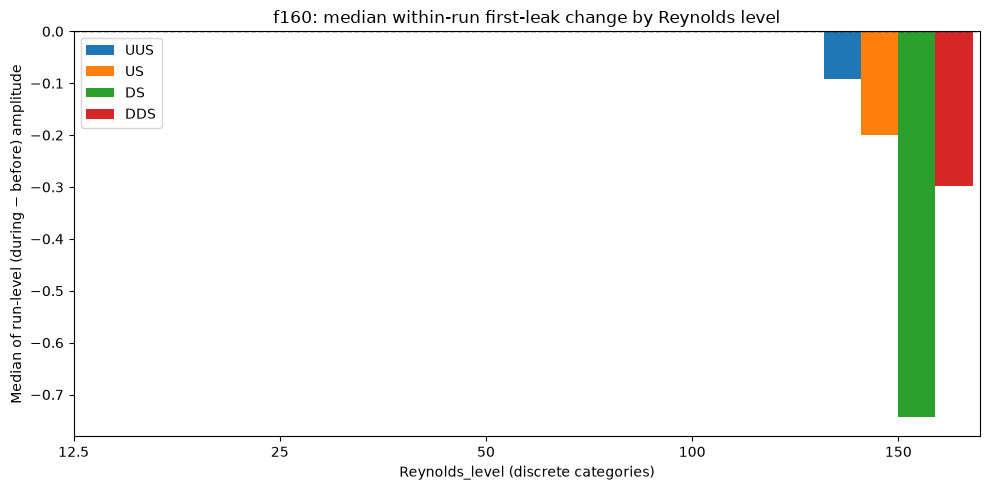

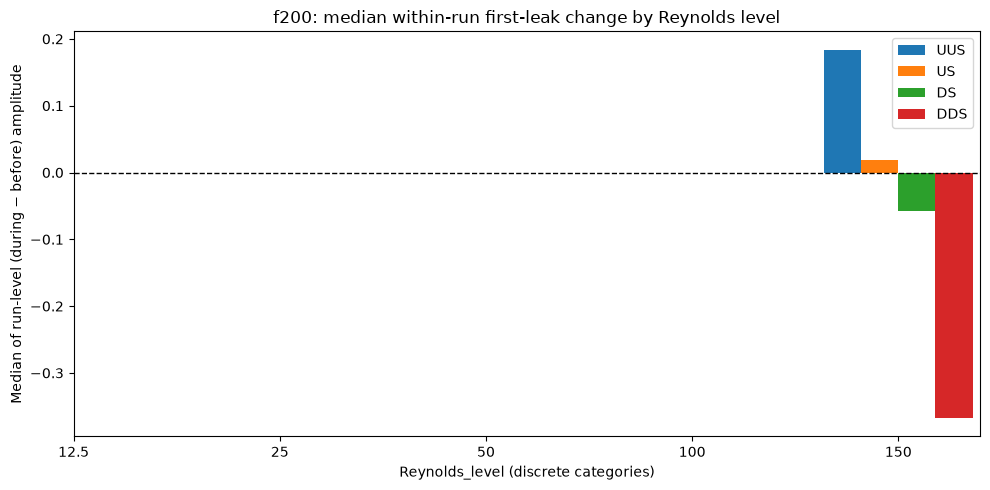

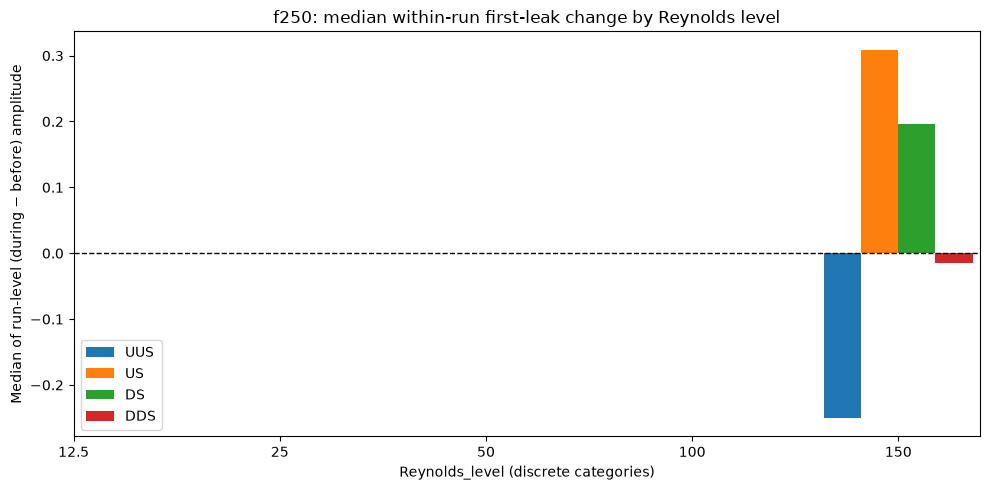

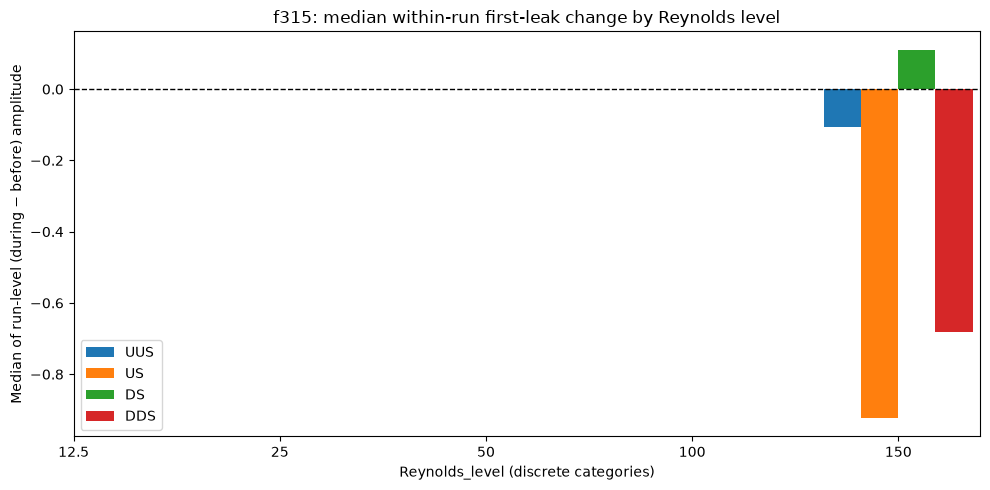

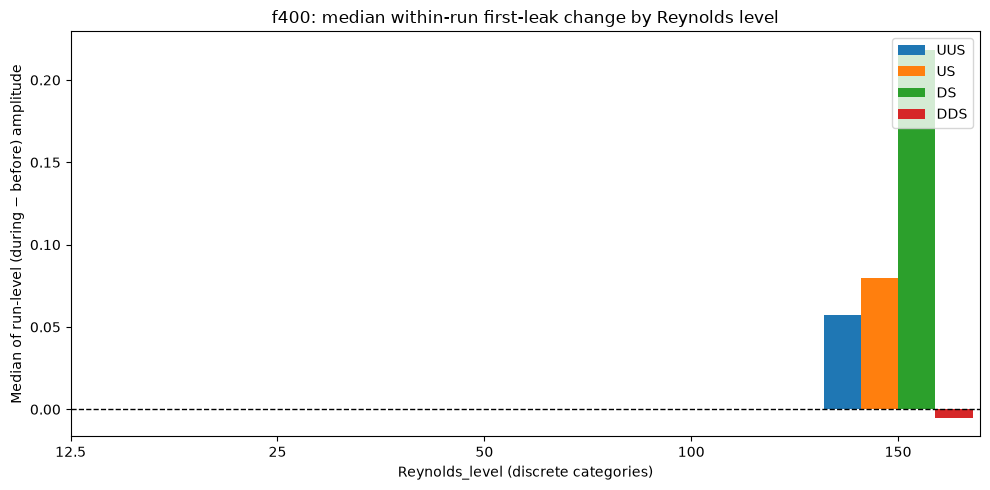

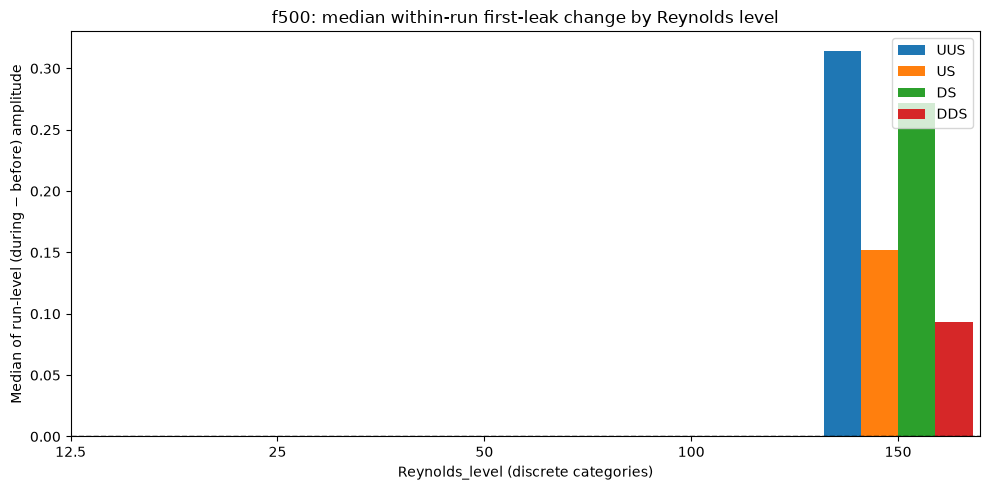

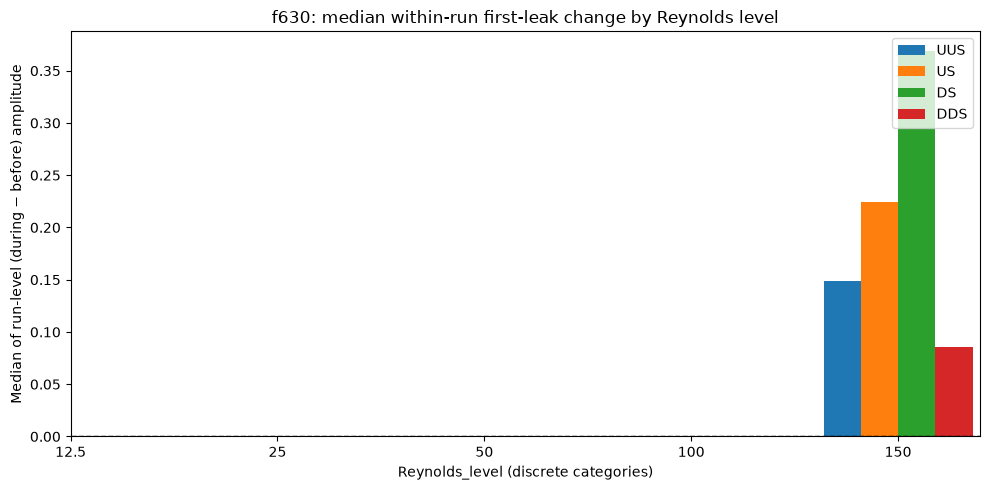

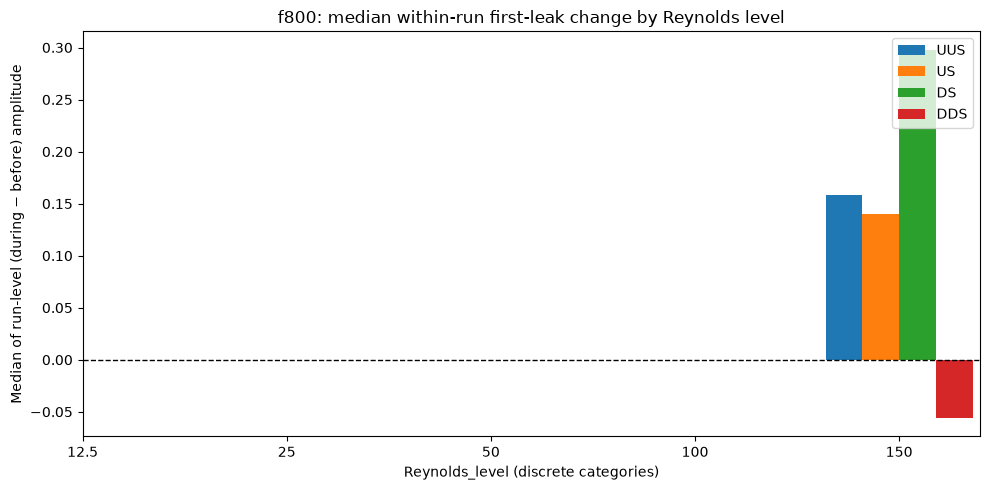

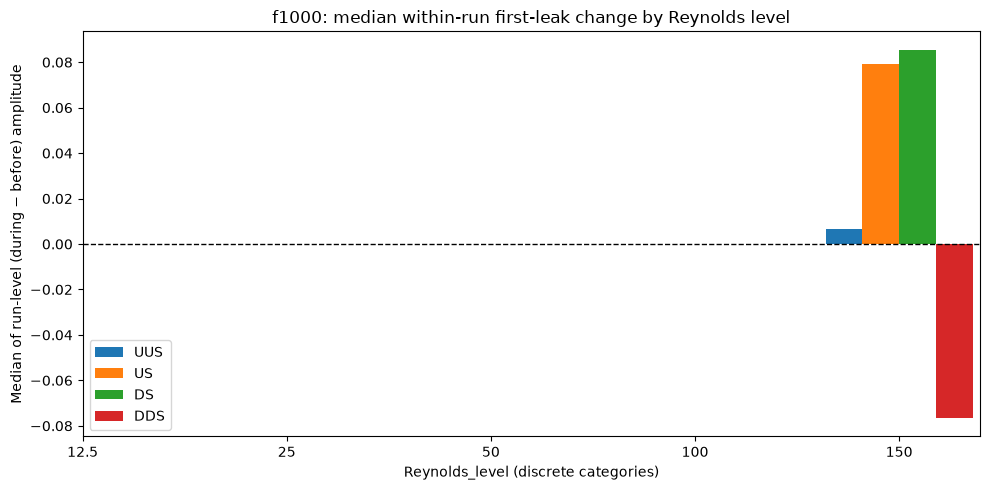

In [9]:
for freq in FREQUENCIES:
    subset = paired[paired['feature'].isin([f'{p}__{freq}' for p in PROBES])]
    if subset.empty:
        print(freq, ': no matched pre/during observations')
        continue
    fig, ax = plt.subplots(figsize=(10,5))
    x = np.arange(len(VALID_LEVELS))
    width = 0.18
    for i, probe in enumerate(PROBES):
        g = subset[subset.feature.eq(f'{probe}__{freq}')]
        grouped = g.groupby('Reynolds_level')['change'].median().reindex(VALID_LEVELS)
        ax.bar(x + (i - 1.5) * width, grouped.values, width=width, label=probe)
    ax.set_xticks(x, [str(int(v)) if float(v).is_integer() else str(v) for v in VALID_LEVELS])
    ax.axhline(0, color='black', linewidth=1, linestyle='--')
    ax.set(title=f'{freq}: median within-run first-leak change by Reynolds level',
           xlabel='Reynolds_level (discrete categories)', ylabel='Median of run-level (during − before) amplitude')
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / f'{freq}_first_leak_change.png', dpi=150)
    plt.show()


## Interpretation and next steps

- A small p-value is evidence of a difference in run-level amplitudes **at that Reynolds level**, not proof that the leak caused it.
- Missing results mean there were no matched healthy and first-leak observations at the same `Reynolds_level`, or insufficient data for the test; they are **not zero effects**.
- Frequencies previously selected for **Reynolds responsiveness** must now demonstrate repeatable leak-associated changes before being considered candidates for detection.
- This notebook does **not** claim DiD, calculate detection accuracy, or set a leak-alarm threshold. Those require a validated control/counterfactual and evaluation on separate runs.

**Files saved to `results/first_leak_frequency_analysis/`:** `first_leak_boundaries.csv`, `paired_run_changes.csv`, `first_leak_frequency_tests.csv`, and one PNG per selected frequency where matched data exist.

**Additional output:** `reynolds_level_availability.csv` reports all five levels for every run, including unmatched groups and their reasons. Bar charts use discrete Reynolds categories rather than connected numeric lines.
- **DiD extension below:** Cross-run healthy data are inspected as candidate controls. Cross-run observations are not assumed to be contemporaneous or parallel without verification.


## 7. Revised cross-run candidate controls: post-first-leak healthy Reynolds-150 observations

The original DiD used elapsed-second-matched healthy controls from other runs and frequently had **no healthy control during the treated first-leak period**. That construction is replaced only here.

For each treated run and a **different** candidate-control run, require all four data groups to exist at the **same categorical Reynolds level (150)** and for the **same feature/frequency**:

1. Treated run — healthy before first leak.
2. Treated run — first-leak observations.
3. Reference run — healthy before its first leak.
4. Reference run — healthy **after its first leak** (newly found in the original CSVs).

Calculate `treated_change = median(2)−median(1)`, `control_change = median(4)−median(3)`, and `did_effect = treated_change−control_change`. Keep every eligible control; no subjective matching or recovery filter is introduced. Save sample counts and the **reference pre/post healthy change** to permit inspection.

**Limit:** Healthy-after and first-leak measurements are *not concurrent*. This is an exploratory DiD-style contrast, not a validated causal DiD. It removes the old missing-control problem, **but does not establish parallel trends or acoustic recovery**.


In [10]:
# Candidate healthy control inventory: pre-leak AND later healthy Re=150 periods.
healthy_inventory_pre = (wide[wide['Leak Event'].eq(0)]
    .groupby(['run_id','Reynolds_level'],sort=True)
    .agg(n_healthy_pre=('elapsed_seconds','size'),
         first_pre_second=('elapsed_seconds','min'),
         last_pre_second=('elapsed_seconds','max'))
    .reset_index())
healthy_inventory_after = (wide_post_healthy[wide_post_healthy['Leak Event'].eq(0)]
    .groupby(['run_id','Reynolds_level'],sort=True)
    .agg(n_healthy_after=('elapsed_seconds','size'),
         first_after_second=('elapsed_seconds','min'),
         last_after_second=('elapsed_seconds','max'))
    .reset_index())
healthy_inventory = healthy_inventory_pre.merge(
    healthy_inventory_after, on=['run_id','Reynolds_level'], how='outer'
).sort_values(['run_id','Reynolds_level'])
healthy_inventory.to_csv(OUT/'did_healthy_control_inventory.csv',index=False)
display(healthy_inventory)

feasibility_rows=[]
did_rows=[]
for (treated_run,level), g in wide.groupby(['run_id','Reynolds_level'],sort=True):
    treated_pre=g[g['Leak Event'].eq(0)]
    treated_post=g[g['Leak Event'].eq(1)]
    if treated_pre.empty or treated_post.empty:
        feasibility_rows.append({'treated_run':treated_run,'Reynolds_level':level,
          'control_run':None,'n_treated_pre':len(treated_pre),'n_treated_first_leak':len(treated_post),
          'n_control_pre':0,'n_control_healthy_after':0,
          'eligible':False,'reason':'treated run lacks pre or first-leak observations at this level'})
        continue
    for control_run in sorted(set(wide['run_id'])-{treated_run}):
        control_pre=wide[(wide['run_id'].eq(control_run)) &
                         (wide['Reynolds_level'].eq(level)) &
                         (wide['Leak Event'].eq(0))]
        control_after=wide_post_healthy[(wide_post_healthy['run_id'].eq(control_run)) &
                                         (wide_post_healthy['Reynolds_level'].eq(level)) &
                                         (wide_post_healthy['Leak Event'].eq(0))]
        eligible=not control_pre.empty and not control_after.empty
        feasibility_rows.append({'treated_run':treated_run,'Reynolds_level':level,
          'control_run':control_run,'n_treated_pre':len(treated_pre),
          'n_treated_first_leak':len(treated_post),
          'n_control_pre':len(control_pre),'n_control_healthy_after':len(control_after),
          'eligible':eligible,'reason':'' if eligible else 'no pre and later healthy reference at same Reynolds level'})
        if not eligible:
            continue
        for feature in features:
            tpre=treated_pre[feature].dropna()
            tpost=treated_post[feature].dropna()
            cpre=control_pre[feature].dropna()
            cpost=control_after[feature].dropna()
            if min(map(len,(tpre,tpost,cpre,cpost)))==0:
                continue
            treated_change=float(tpost.median()-tpre.median())
            control_change=float(cpost.median()-cpre.median())
            did_rows.append({'treated_run':treated_run,'control_run':control_run,
               'Reynolds_level':level,'feature':feature,
               'n_treated_pre':len(tpre),'n_treated_first_leak':len(tpost),
               'n_control_pre':len(cpre),'n_control_healthy_after':len(cpost),
               'treated_change':treated_change,'control_change':control_change,
               'did_effect':treated_change-control_change})
feasibility=pd.DataFrame(feasibility_rows)
feasibility.to_csv(OUT/'did_control_feasibility.csv',index=False)
did=pd.DataFrame(did_rows,columns=['treated_run','control_run','Reynolds_level','feature',
     'n_treated_pre','n_treated_first_leak','n_control_pre','n_control_healthy_after',
     'treated_change','control_change','did_effect'])
did.to_csv(OUT/'did_cross_run_contrasts.csv',index=False)
print('Eligible treated/reference run pairs:',int(feasibility['eligible'].sum()))
print('DiD-style feature contrasts:', len(did))
display(feasibility)
if did.empty:
    print('NO ELIGIBLE DiD-STYLE CONTRAST: no matched Reynolds-level healthy reference episodes.')
else:
    print('Exploratory DiD-style contrasts (recovery and parallel trends NOT established):')
    display(did.head(40))


,run_id,Reynolds_level,n_healthy_pre,first_pre_second,last_pre_second,n_healthy_after,first_after_second,last_after_second
0,1211_1,12.5,600,0.0,599.0,NaN,NaN,NaN
1,1211_1,25.0,600,600.0,1199.0,NaN,NaN,NaN
2,1211_1,50.0,600,1200.0,1799.0,NaN,NaN,NaN
3,1211_1,100.0,600,1800.0,2399.0,NaN,NaN,NaN
4,1211_1,150.0,600,2400.0,2999.0,300.0,3600.0,3899.0
5,1212_1,12.5,600,0.0,599.0,NaN,NaN,NaN
6,1212_1,25.0,600,600.0,1199.0,NaN,NaN,NaN
7,1212_1,50.0,600,1200.0,1799.0,NaN,NaN,NaN
8,1212_1,100.0,600,1800.0,2399.0,NaN,NaN,NaN
9,1212_1,150.0,600,2400.0,2999.0,300.0,3600.0,3899.0


Eligible treated/reference run pairs: 20
DiD-style feature contrasts: 1260


,treated_run,Reynolds_level,control_run,n_treated_pre,n_treated_first_leak,n_control_pre,n_control_healthy_after,eligible,reason
0,1211_1,12.5,NaN,600,0,0,0,False,treated run lacks pre or first-leak observatio...
1,1211_1,25.0,NaN,600,0,0,0,False,treated run lacks pre or first-leak observatio...
2,1211_1,50.0,NaN,600,0,0,0,False,treated run lacks pre or first-leak observatio...
3,1211_1,100.0,NaN,600,0,0,0,False,treated run lacks pre or first-leak observatio...
4,1211_1,150.0,1212_1,600,600,600,300,True,
5,1211_1,150.0,1212_2,600,600,600,300,True,
6,1211_1,150.0,1213_1,600,600,600,300,True,
7,1211_1,150.0,1213_2,600,600,600,300,True,
8,1212_1,12.5,NaN,600,0,0,0,False,treated run lacks pre or first-leak observatio...
9,1212_1,25.0,NaN,600,0,0,0,False,treated run lacks pre or first-leak observatio...


Exploratory DiD-style contrasts (recovery and parallel trends NOT established):


,treated_run,control_run,Reynolds_level,feature,n_treated_pre,n_treated_first_leak,n_control_pre,n_control_healthy_after,treated_change,control_change,did_effect
0,1211_1,1212_1,150.0,UUS__f160,600,600,600,300,-0.091462,0.112461,-0.203923
1,1211_1,1212_1,150.0,UUS__f200,600,600,600,300,0.183763,-0.052527,0.236290
2,1211_1,1212_1,150.0,UUS__f250,600,600,600,300,-0.250282,-0.845354,0.595072
3,1211_1,1212_1,150.0,UUS__f315,600,600,600,300,-0.442906,0.304817,-0.747724
4,1211_1,1212_1,150.0,UUS__f400,600,600,600,300,-0.948771,-0.848516,-0.100256
5,1211_1,1212_1,150.0,UUS__f500,600,600,600,300,-0.271555,-0.242685,-0.028870
6,1211_1,1212_1,150.0,UUS__f630,600,600,600,300,-0.011228,-0.373334,0.362106
7,1211_1,1212_1,150.0,UUS__f800,600,600,600,300,0.158279,0.168753,-0.010474
8,1211_1,1212_1,150.0,UUS__f1000,600,600,600,300,1.653810,0.051973,1.601837
9,1211_1,1212_1,150.0,US__f160,600,600,600,300,-0.067374,-1.395688,1.328315


## 8. DiD-style contrasts and original visualizations

These display the differences of changes using candidate reference healthy episodes after the first leak, replacing the earlier elapsed-time-matched controls. Figures are exploratory and do not establish a causal leak effect.

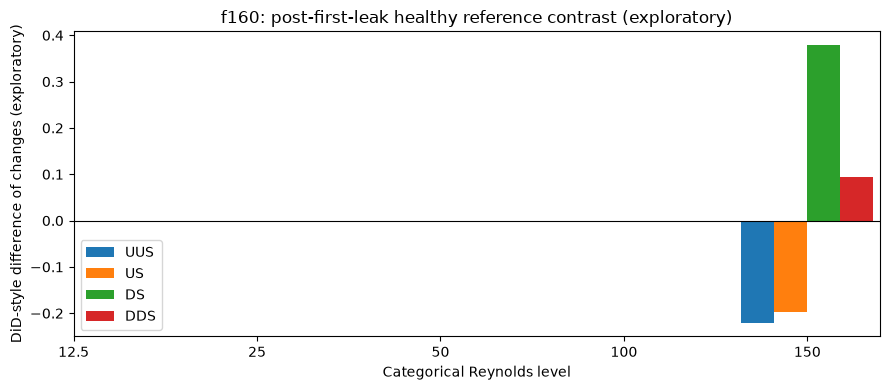

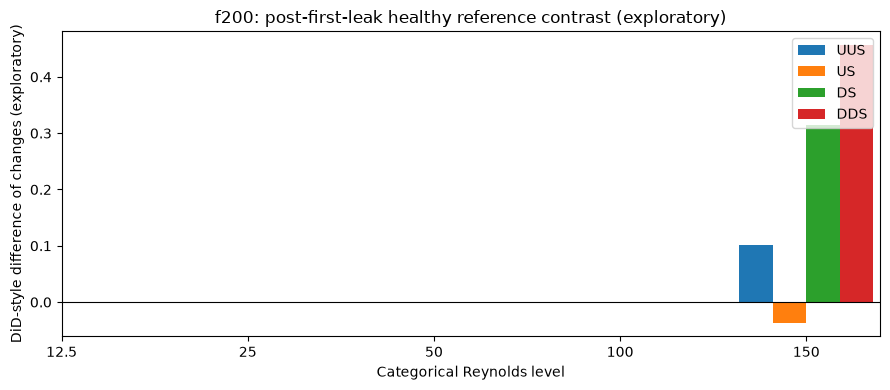

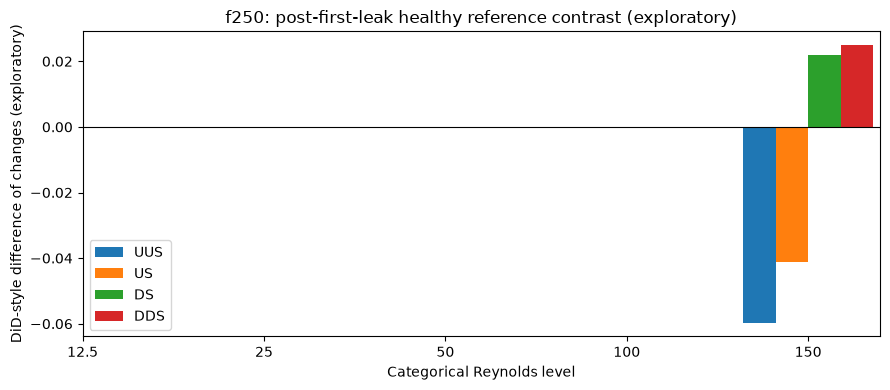

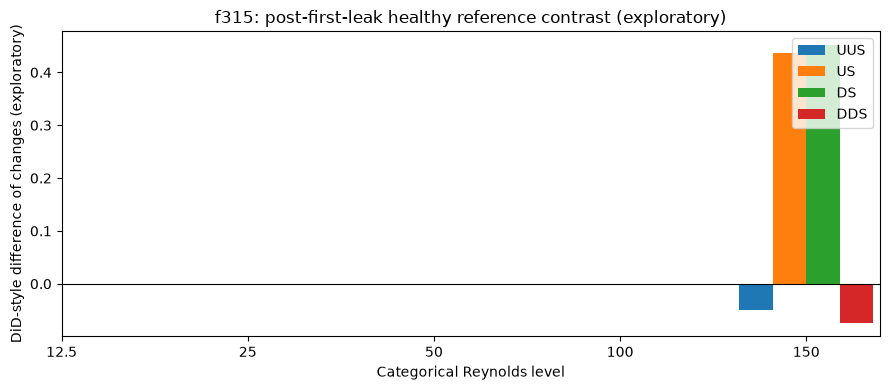

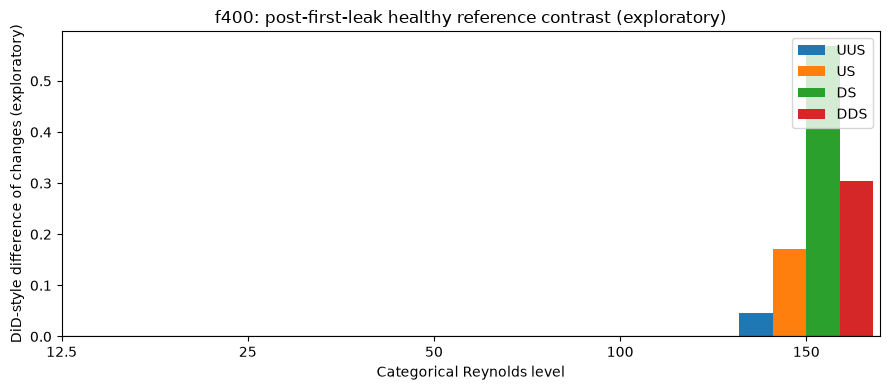

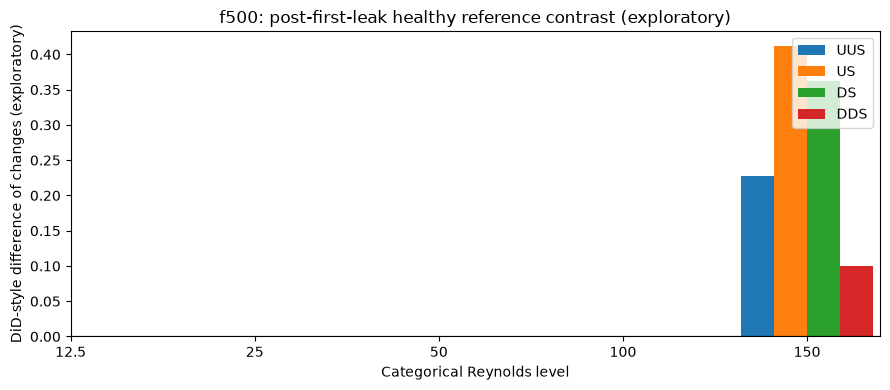

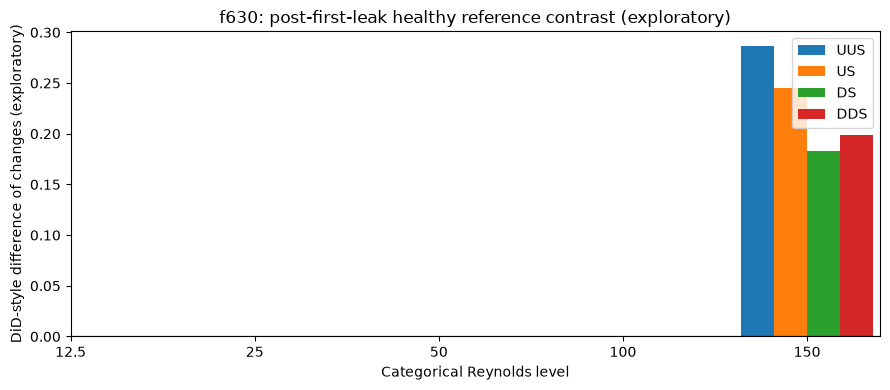

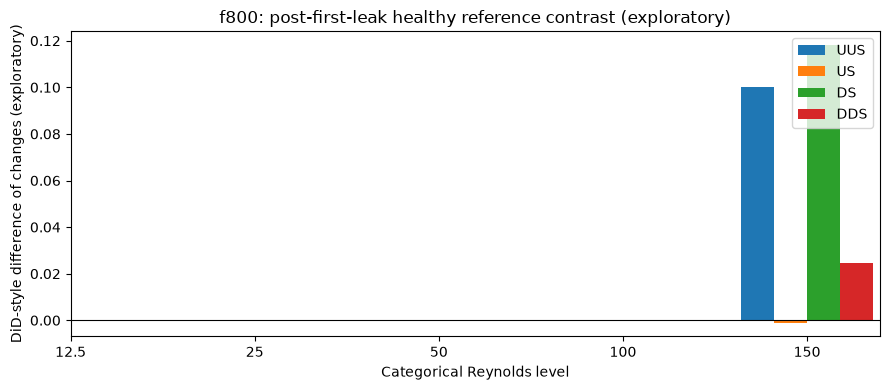

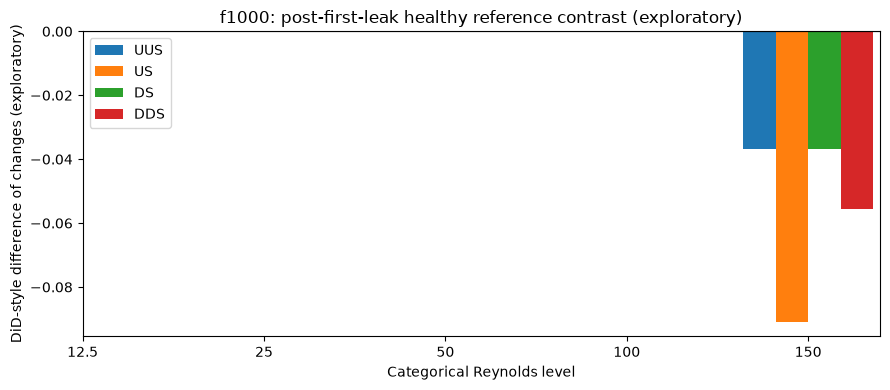

In [11]:
if did.empty:
    print('DiD effect chart unavailable: zero eligible treated/control comparisons.')
else:
    for freq in FREQUENCIES:
        sub=did[did['feature'].isin([f'{p}__{freq}' for p in PROBES])]
        if sub.empty:
            print(f'{freq}: no DiD effects available')
            continue
        grouped=sub.groupby(['Reynolds_level','feature'])['did_effect'].median().unstack('feature')
        fig,ax=plt.subplots(figsize=(9,4))
        x=np.arange(len(VALID_LEVELS))
        width=0.18
        for j,probe in enumerate(PROBES):
            vals=grouped.reindex(VALID_LEVELS).get(f'{probe}__{freq}',pd.Series(index=VALID_LEVELS,dtype=float))
            ax.bar(x+(j-1.5)*width,vals.to_numpy(),width,label=probe)
        ax.axhline(0,color='black',linewidth=.8)
        ax.set_xticks(x, [str(v).removesuffix('.0') for v in VALID_LEVELS])
        ax.set_xlabel('Categorical Reynolds level')
        ax.set_ylabel('DiD-style difference of changes (exploratory)')
        ax.set_title(f'{freq}: post-first-leak healthy reference contrast (exploratory)')
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUT/f'{freq}_did_effect.png',dpi=160)
        plt.show()


## 9. Exploratory run-level inference (original calculations retained)

For each feature, average the available contrasts across candidate control runs within each treated run, then compute the original across-run t-based summary. **Do not interpret these p-values as confirmatory**: a run can appear as both treated and candidate control, the controls are shared across contrasts, recovery is unvalidated, and the periods are nonconcurrent. The tests are also unadjusted for multiple comparisons. A nominal `p < 0.05` means only that the calculated exploratory test meets that threshold.

In [16]:
# Exploratory inference from treated-run summaries, not individual matched seconds.
# Shared control runs can induce dependence: these p-values are NOT confirmatory.
from scipy import stats

if did.empty:
    did_run = pd.DataFrame(columns=['Reynolds_level','feature','treated_run',
                                    'n_control_runs','mean_did_effect'])
    did_inference = pd.DataFrame(columns=['Reynolds_level','feature','n_treated_runs',
        'mean_did_effect','sd_across_treated_runs','ci95_low','ci95_high','p_value',
        'inference_status'])
else:
    did_run = (did.groupby(['Reynolds_level','feature','treated_run'], as_index=False)
        .agg(n_control_runs=('control_run','nunique'),
             mean_did_effect=('did_effect','mean')))
    rows = []
    for (level, feature), group in did_run.groupby(['Reynolds_level','feature'], sort=True):
        x = group['mean_did_effect'].dropna().to_numpy(dtype=float)
        count = len(x)
        mean = float(np.mean(x)) if count else np.nan
        sd = float(np.std(x, ddof=1)) if count >= 2 else np.nan
        low = high = pval = np.nan
        if count < 2:
            status = 'unavailable: fewer than two treated runs'
        elif not np.isfinite(sd) or sd == 0:
            status = 'unavailable: zero or undefined run-level variance'
        else:
            sem = sd / np.sqrt(count)
            tstat = mean / sem
            pval = float(2 * stats.t.sf(abs(tstat), df=count - 1))
            half_width = float(stats.t.ppf(0.975, df=count - 1) * sem)
            low, high = mean - half_width, mean + half_width
            status = 'exploratory only: shared controls may induce dependence'
        rows.append({'Reynolds_level': level, 'feature': feature,
            'n_treated_runs': count, 'mean_did_effect': mean,
            'sd_across_treated_runs': sd, 'ci95_low': low,
            'ci95_high': high, 'p_value': pval, 'inference_status': status})
    did_inference = pd.DataFrame(rows)

did_run.to_csv(OUT / 'did_treated_run_summaries.csv', index=False)
did_inference.to_csv(OUT / 'did_exploratory_inference.csv', index=False)
print('EXPLORATORY DiD inference; shared controls and unverified parallel trends limit validity.')
display(did_inference[did_inference['p_value']< .9].sort_values('p_value'))


EXPLORATORY DiD inference; shared controls and unverified parallel trends limit validity.


,Reynolds_level,feature,n_treated_runs,mean_did_effect,sd_across_treated_runs,ci95_low,ci95_high,p_value,inference_status
24,150.0,DS__f500,5,0.356732,0.212857,0.092434,0.621029,0.019991,exploratory only: shared controls may induce d...
42,150.0,US__f500,5,0.452045,0.332968,0.038610,0.865480,0.038563,exploratory only: shared controls may induce d...
8,150.0,DDS__f800,5,0.060233,0.047083,0.001772,0.118694,0.045902,exploratory only: shared controls may induce d...
7,150.0,DDS__f630,5,0.288158,0.245726,-0.016951,0.593267,0.058664,exploratory only: shared controls may induce d...
23,150.0,DS__f400,5,0.663022,0.616664,-0.102668,1.428712,0.074021,exploratory only: shared controls may induce d...
41,150.0,US__f400,5,0.525178,0.503705,-0.100254,1.150611,0.080130,exploratory only: shared controls may induce d...
62,150.0,UUS__f800,5,0.171115,0.168779,-0.038452,0.380682,0.086011,exploratory only: shared controls may induce d...
44,150.0,US__f800,5,0.087092,0.094060,-0.029699,0.203882,0.107179,exploratory only: shared controls may induce d...
2,150.0,DDS__f200,5,0.354249,0.399814,-0.142185,0.850683,0.118634,exploratory only: shared controls may induce d...
14,150.0,DS-DDS__f400,5,0.455068,0.533870,-0.207820,1.117955,0.129339,exploratory only: shared controls may induce d...


## 10. Interpretation

- `did_cross_run_contrasts.csv`: **exploratory DiD-style** differences of changes (not validated causal DiD).
- `did_control_feasibility.csv`: all treated/reference-run coverage and absent groups.
- `did_healthy_control_inventory.csv`: separate healthy coverage **before and after** each reference run's first leak.
- `post_first_leak_healthy_inventory.csv`: per original probe CSV, number of healthy rows at Reynolds 150 *after* first leak.
- The original paired pre/first-leak results and figures are retained as descriptive comparisons.
- Post-first-leak healthy data may contain recovery/carryover effects; same Reynolds level does not guarantee the same acoustic plateau, and nonconcurrent comparisons do not establish parallel trends.
- Nominal p-values are **not** causally identified or multiplicity-adjusted. See the boxplots below before drawing any conclusions.

## 11. Healthy-before, first-leak, healthy-after boxplots for important and nominally significant features

At Reynolds level **150**, for each run, show the **same feature** in three explicitly labeled episodes: healthy **before first leak**, **during first leak**, and **healthy after first leak**. The healthy-after observations come from the original untruncated files. The three previously highlighted spatial features are **always included**: `US-DS__f400`, `US-DS__f500`, `UUS-US__f630`. Additionally, include *all* features with **nominal unadjusted `p < 0.05`** in either original paired tests or the exploratory DiD-style tests. Selection reasons are saved in CSV; no significant feature is hidden by an arbitrary top-N cutoff.

A boxplot comparison is **visual evidence only**: individual timestamps are correlated, the post-first-leak acoustic state may not have recovered, and neither the boxplot nor the exploratory t-test validates a causal DiD. Boxplots omit outlier markers (`showfliers=False`), matching the previously requested presentation; they do not discard those data from any calculation.

Important/nominal features for boxplots: 10


,feature,specifically_requested,nominal_p_lt_0_05_paired,nominal_p_lt_0_05_did_style
0,DS__f500,True,False,True
1,US__f500,True,False,True
2,US-DS__f400,True,False,False
3,US-DS__f500,True,False,False
4,UUS-US__f630,True,False,False
5,DDS__f315,False,True,False
6,DDS__f800,False,False,True
7,DS-DDS__f800,False,True,False
8,DS__f800,False,True,False
9,US__f250,False,True,False


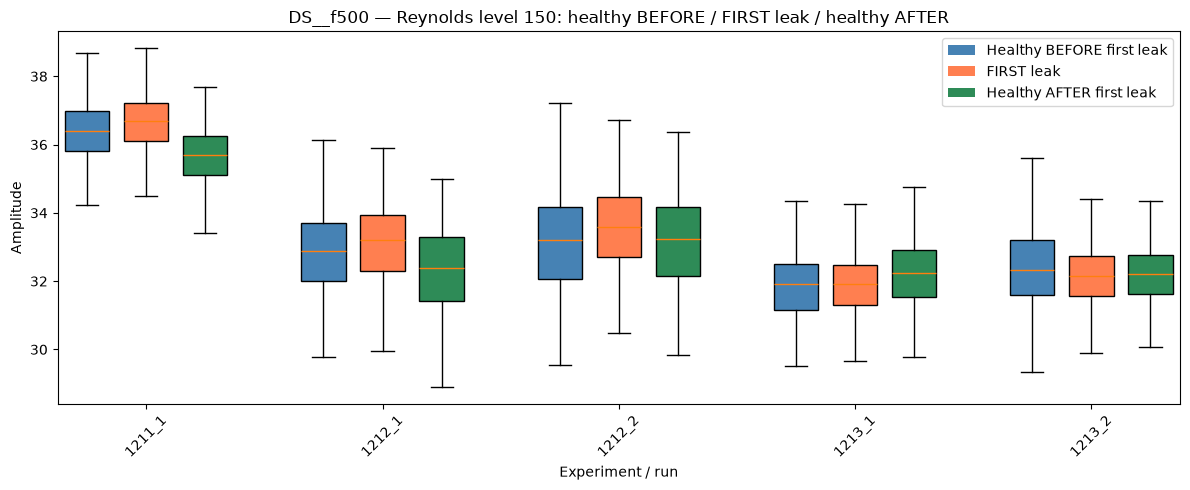

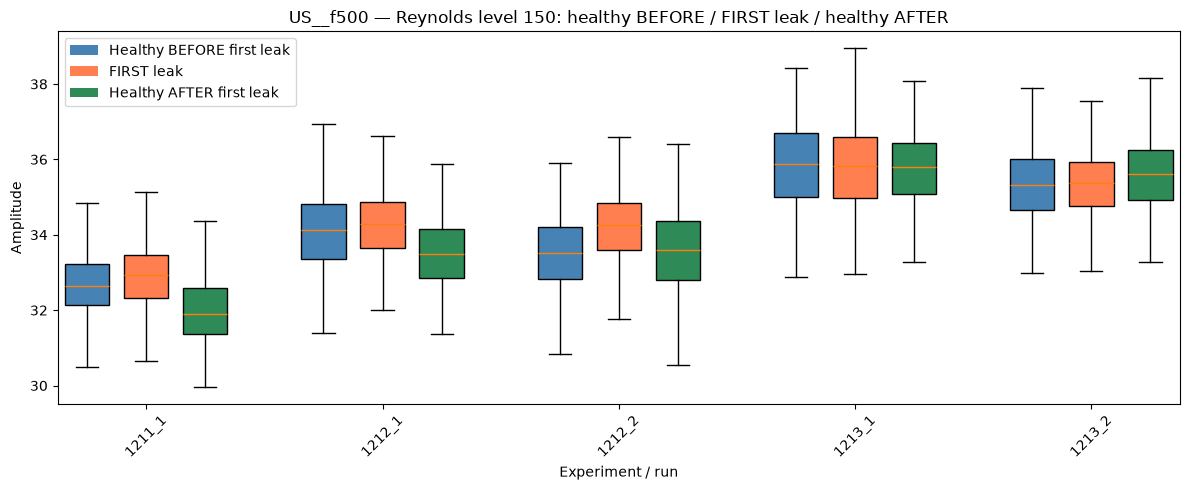

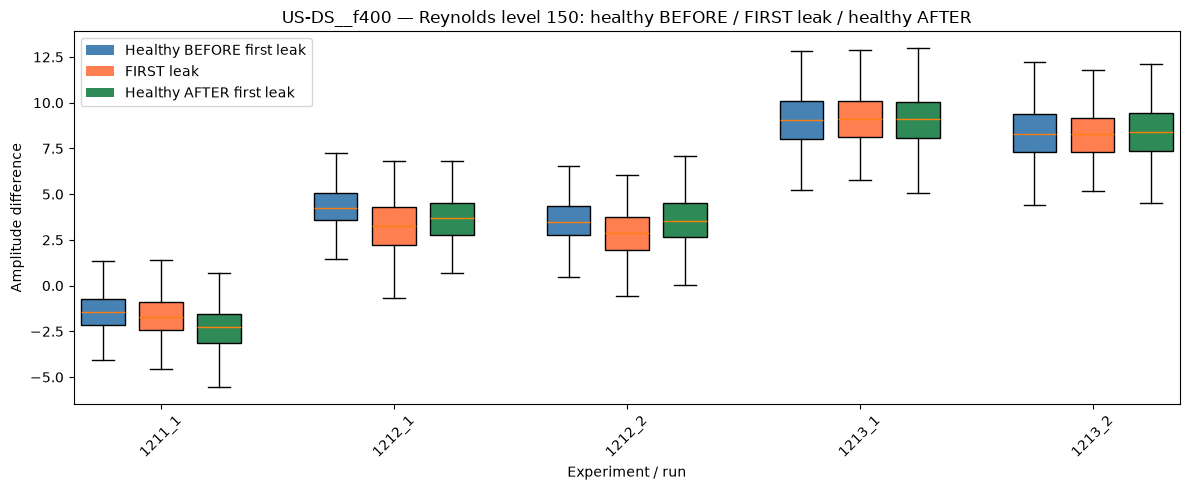

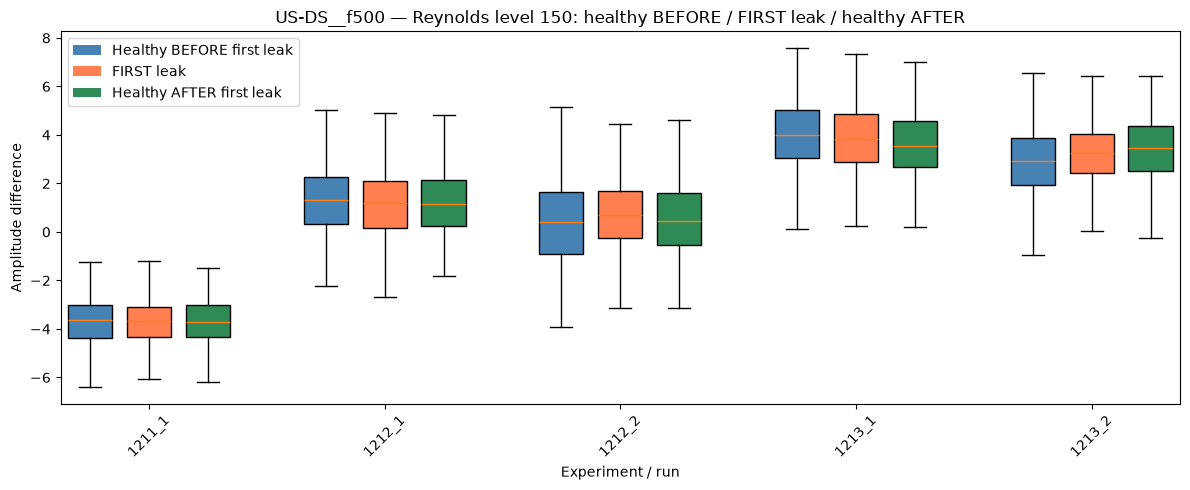

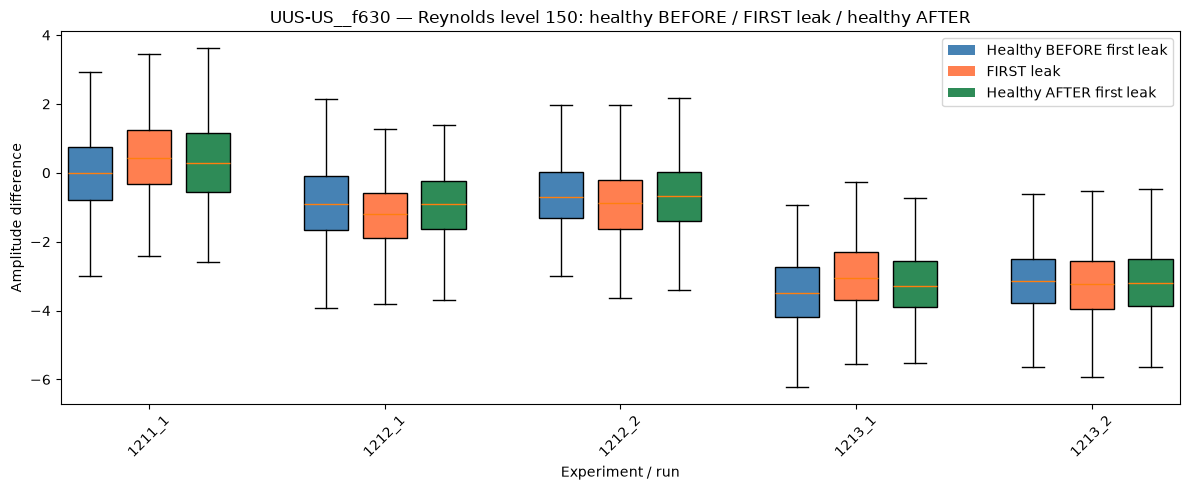

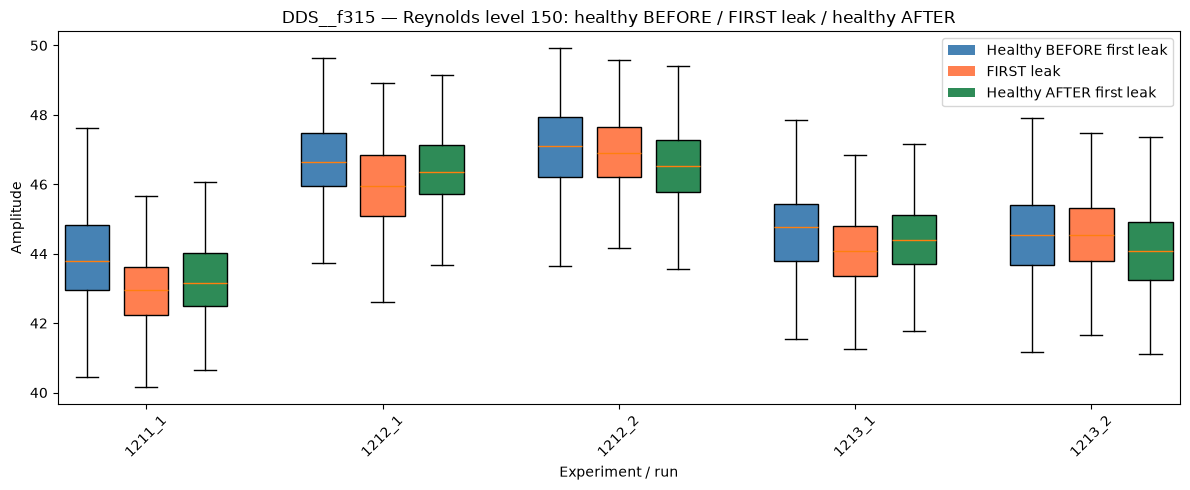

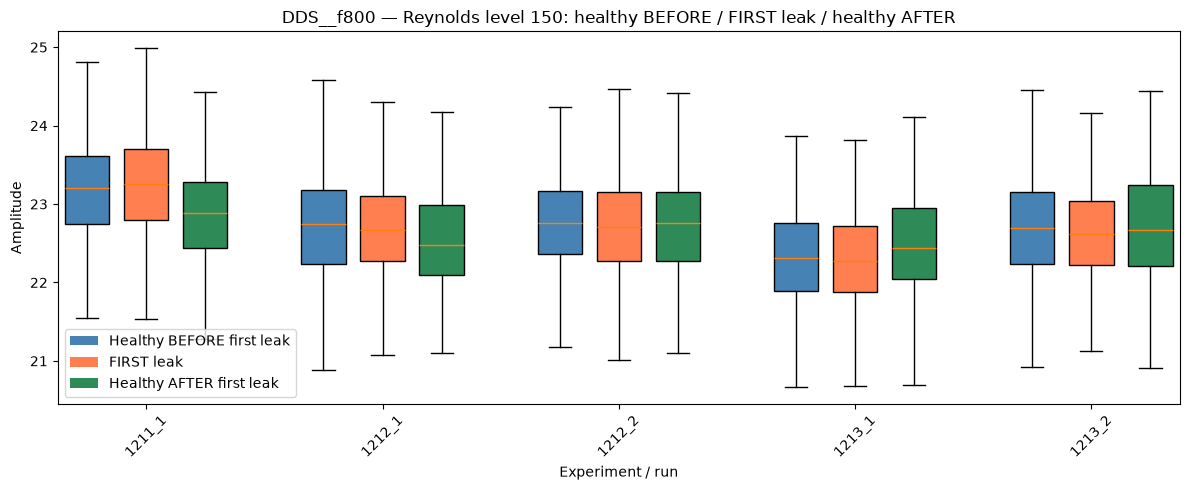

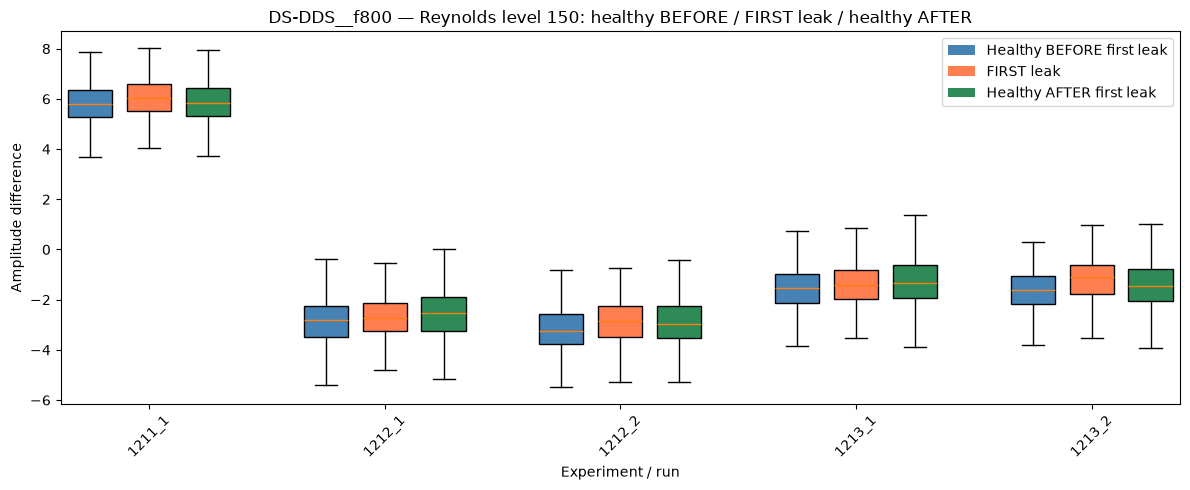

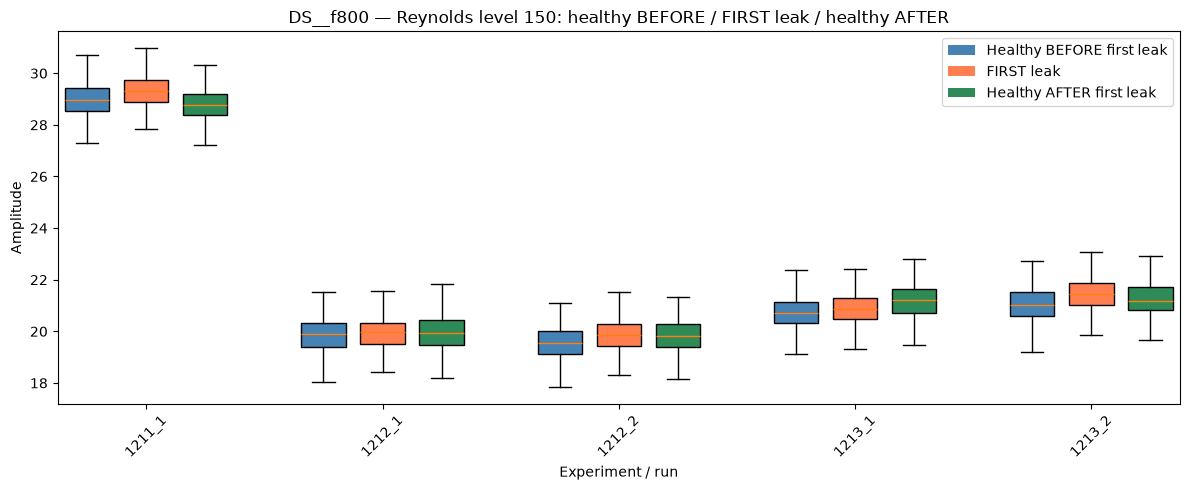

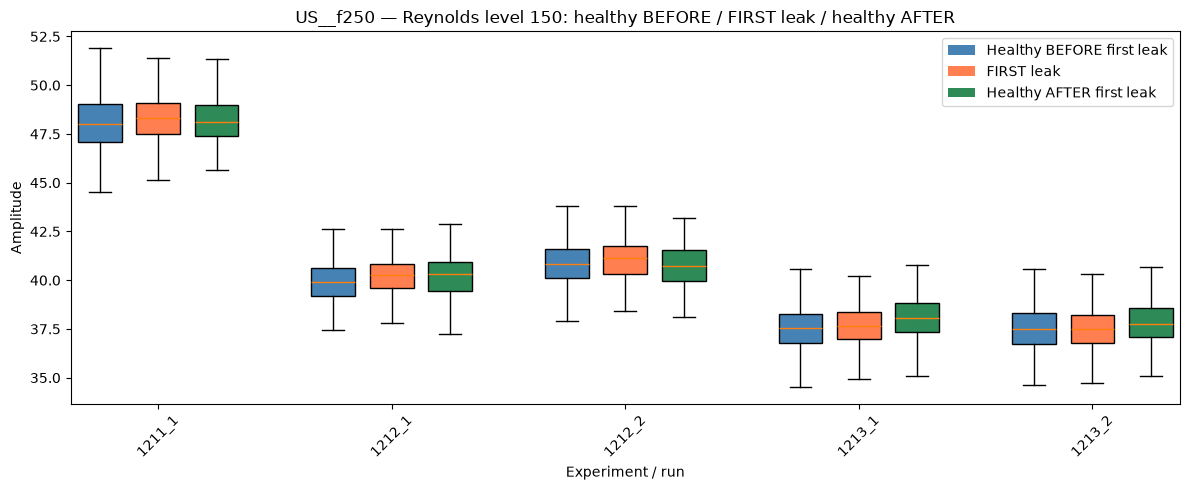

In [18]:
# Preserve the three specifically requested spatial features, then add ALL nominal results.
IMPORTANT_FEATURES = ('DS__f500','US__f500','US-DS__f400', 'US-DS__f500', 'UUS-US__f630')
LEVEL_FOR_BOXPLOTS = 150.0
paired_nominal = set(summary.loc[
    summary['Reynolds_level'].eq(LEVEL_FOR_BOXPLOTS) & summary['p_value'].lt(0.05), 'feature'
].dropna())
did_nominal = set(did_inference.loc[
    did_inference['Reynolds_level'].eq(LEVEL_FOR_BOXPLOTS) &
    did_inference['p_value'].lt(0.05), 'feature'
].dropna())
boxplot_features = list(IMPORTANT_FEATURES) + sorted(
    (paired_nominal | did_nominal) - set(IMPORTANT_FEATURES)
)
selection = pd.DataFrame([
    {'feature':f, 'specifically_requested':f in IMPORTANT_FEATURES,
     'nominal_p_lt_0_05_paired':f in paired_nominal,
     'nominal_p_lt_0_05_did_style':f in did_nominal}
    for f in boxplot_features
])
selection.to_csv(OUT/'selected_boxplot_features.csv',index=False)
print('Important/nominal features for boxplots:',len(boxplot_features))
display(selection)

runs_for_plots = sorted(wide['run_id'].unique())
legend_items = [
    Patch(facecolor='steelblue', label='Healthy BEFORE first leak'),
    Patch(facecolor='coral', label='FIRST leak'),
    Patch(facecolor='seagreen', label='Healthy AFTER first leak')
]
for feature in boxplot_features:
    fig, ax = plt.subplots(figsize=(max(12, len(runs_for_plots)*2.1), 5))
    present = False
    for i, run in enumerate(runs_for_plots):
        original = wide.loc[wide['run_id'].eq(run) & wide['Reynolds_level'].eq(LEVEL_FOR_BOXPLOTS)]
        after = wide_post_healthy.loc[
            wide_post_healthy['run_id'].eq(run) &
            wide_post_healthy['Reynolds_level'].eq(LEVEL_FOR_BOXPLOTS)]
        groups = (
            (original.loc[original['Leak Event'].eq(0), feature].dropna(), i*4, 'steelblue'),
            (original.loc[original['Leak Event'].eq(1), feature].dropna(), i*4+1, 'coral'),
            (after.loc[after['Leak Event'].eq(0), feature].dropna(), i*4+2, 'seagreen')
        )
        for values, position, color in groups:
            if values.empty:
                continue
            present = True
            ax.boxplot(values.to_numpy(), positions=[position], widths=0.75,
                       patch_artist=True, boxprops={'facecolor':color},
                       showfliers=False)
    ax.set_xticks([i*4+1 for i in range(len(runs_for_plots))])
    ax.set_xticklabels(runs_for_plots, rotation=45)
    ax.set_xlabel('Experiment / run')
    ax.set_ylabel('Amplitude' if '-' not in feature.split('__')[0] else 'Amplitude difference')
    ax.set_title(f'{feature} — Reynolds level 150: healthy BEFORE / FIRST leak / healthy AFTER')
    ax.legend(handles=legend_items, loc='best')
    fig.tight_layout()
    fig.savefig(OUT/f'boxplot_{feature.replace("/", "_")}_Re150.png',dpi=160,bbox_inches='tight')
    if not present:
        print('No data available for:', feature)
    plt.show()


## 12. Validation checklist and limitations

- **Preserved:** First-leak boundaries, Reynolds-level availability, original run-level pre/first-leak medians, paired t-based summaries, nine-frequency per-probe figures, four-probe synchronization, spatial differences, DiD-style difference-of-changes charts, and original exploratory treated-run inference.
- **Modified:** Read raw untruncated experiment CSVs and replace the DiD control construction with the later `Leak Event=0`, Reynolds-150 observations from other runs. *Do not* assert elapsed-second matching across nonconcurrent episodes.
- **Added:** Per-file availability and per-run pre/post healthy inventory; selected-feature listing; healthy-before / first-leak / healthy-after boxplots for the three requested spatial features plus every nominally significant result.
- **Not established by this notebook:** Parallel trends, post-leak acoustic recovery, an uncontaminated counterfactual, independent control-based inference, or a causal leak effect. No feature is described as confirmed significant after multiple-testing correction.


,treated_change,mean_control_change,did_effect,recalculated
treated_run,,,,
1211_1,0.2721,-0.0708,0.3429,0.3429
1212_1,0.3260,-0.1274,0.4534,0.4534
1212_2,0.3651,-0.2535,0.6185,0.6185
1213_1,-0.0020,-0.3344,0.3324,0.3324
1213_2,-0.1790,-0.2155,0.0365,0.0365


Mean treated change: 0.15643520000000066
Mean control change: -0.20029639999999915
Mean DiD-style effect: 0.3567315999999998


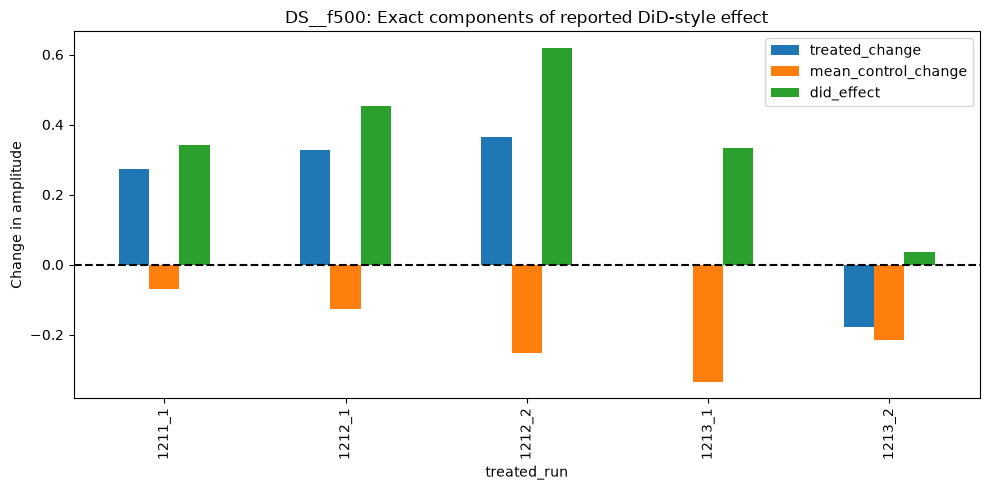

In [19]:
feature = "DS__f500"

check = did[
    did["feature"].eq(feature) &
    did["Reynolds_level"].eq(150)
]

audit = check.groupby("treated_run").agg(
    treated_change=("treated_change", "first"),
    mean_control_change=("control_change", "mean"),
    did_effect=("did_effect", "mean")
)

audit["recalculated"] = (
    audit["treated_change"] - audit["mean_control_change"]
)

display(audit.round(4))

assert np.allclose(audit["did_effect"], audit["recalculated"])

print("Mean treated change:", audit["treated_change"].mean())
print("Mean control change:", audit["mean_control_change"].mean())
print("Mean DiD-style effect:", audit["did_effect"].mean())

audit[["treated_change", "mean_control_change", "did_effect"]].plot(
    kind="bar", figsize=(10, 5),
    title="DS__f500: Exact components of reported DiD-style effect"
)
plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Change in amplitude")
plt.tight_layout()
plt.show()